In [ ]:
##Análisis de Texto 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df_final = pd.read_csv("../Práctica 1/glp1_limpio.csv", parse_dates=['FECHA'])

In [2]:
df_final['PRESENTACION'].value_counts().head(20)

PRESENTACION
Trulicity 1.5mg/0.5ml solution for injection pre-filled pens    426594
Ozempic 1mg/0.74ml inj 3ml pre-filled pens                      304752
Victoza 6mg/ml solution for injection 3ml pre-filled pens       270955
Trulicity 3mg/0.5ml solution for injection pre-filled pens      245095
Liraglutide 6mg/1ml inj 3ml pre-filled disposable devices       241956
Dulaglutide 1.5mg/0.5ml inj pre-filled disposable devices       234018
Ozempic 0.5mg/0.37ml inj 1.5ml pre-filled pens                  211463
Trulicity 0.75mg/0.5ml inj pre-filled pens                      174378
Trulicity 4.5mg/0.5ml solution for injection pre-filled pens    143644
Mounjaro KwikPen 5mg/0.6ml inj 2.4ml pre-filled pens            119014
Ozempic 0.25mg/0.19ml inj 1.5ml pre-filled pens                 118548
Rybelsus 7mg tablets                                            114969
Semaglutide 0.5mg/0.37ml inj 1.5ml pf dispos dev                105654
Rybelsus 14mg tablets                                           

In [6]:
# 1) Primera palabra de cada presentación
df_final['PRIMERA_PALABRA'] = df_final['PRESENTACION'].str.split().str[0]   

print(df_final['PRIMERA_PALABRA'].nunique())
print(df_final['PRIMERA_PALABRA'].value_counts())

# 2) Filas vs recetas
comparacion = df_final.groupby('PRIMERA_PALABRA').agg(
    filas=('PRESENTACION', 'count'),   
    recetas=('ITEMS', 'sum')         
)
comparacion['rank_filas'] = comparacion['filas'].rank(ascending=False)   
comparacion['rank_recetas'] = comparacion['recetas'].rank(ascending=False)
comparacion['recetas_por_fila'] = comparacion['recetas'] / comparacion['filas']
print(comparacion.sort_values('recetas', ascending=False))

20
PRIMERA_PALABRA
Trulicity       989711
Ozempic         635143
Semaglutide     592111
Dulaglutide     402326
Mounjaro        390409
Rybelsus        335425
Victoza         270955
Tirzepatide     268420
Liraglutide     241956
Exenatide        83168
Bydureon         63064
Lixisenatide     31683
Saxenda          13977
Byetta           11609
Wegovy            8484
Lyxumia           6319
Zegluxen          2725
Diavic            1116
Nevolat             88
Biolide             54
Name: count, dtype: int64
                  filas  recetas  rank_filas  rank_recetas  recetas_por_fila
PRIMERA_PALABRA                                                             
Trulicity        989711  3857438         1.0           1.0          3.897540
Mounjaro         390409  2413948         5.0           2.0          6.183126
Ozempic          635143  2348732         2.0           3.0          3.697958
Semaglutide      592111  1512120         3.0           4.0          2.553778
Rybelsus         335425  1083490 

In [7]:
import numpy as np

# 1) ¿es nombre comercial?
df_final['ES_COMERCIAL'] = df_final['PRIMERA_PALABRA'] != df_final['SUSTANCIA']   

# 2) forma: tableta o inyección
df_final['FORMA'] = np.where(df_final['PRESENTACION'].str.contains('tablets', case=False), 'Tableta', 'Inyección')   # pista: palabra que aparece en las tabletas

# 3) dosis (el número que va justo antes de la unidad)
df_final['DOSIS'] = df_final['PRESENTACION'].str.extract(r'(\d+\.?\d*)mg', expand=False).astype(float)  

# revisiones
print(df_final['ES_COMERCIAL'].value_counts())
print(df_final['FORMA'].value_counts())
print("sin dosis:", df_final['DOSIS'].isna().sum())
print(df_final[df_final['DOSIS'].isna()]['PRESENTACION'].unique()[:10])

ES_COMERCIAL
True     2729079
False    1619664
Name: count, dtype: int64
FORMA
Inyección    3742853
Tableta       605890
Name: count, dtype: int64
sin dosis: 96167
['Exenatide 10micrograms/0.04ml inj 2.4ml pf dispos dev'
 'Byetta 10micrograms/0.04ml inj 2.4ml pre-filled pens'
 'Byetta 5micrograms/0.02ml inj 1.2ml pre-filled pens'
 'Exenatide 5micrograms/0.02ml inj 1.2ml pf dispos dev'
 'Lixisenatide 20micrograms/0.2ml inj 3ml pf dispos dev'
 'Lyxumia 20micrograms/0.2ml inj 3ml pre-filled pens'
 'Lixisenatide 10micrograms/0.2ml inj 3ml pf dispos dev'
 'Lyxumia 10micrograms/0.2ml inj 3ml pre-filled pens'
 'Lyxumia 10micrograms/20micrograms treatment initiation pack'
 'Lixisenatide 10microg/0.2ml and 20microg/0.2ml inj']


In [8]:
tirz = df_final[df_final['SUSTANCIA'] == 'Tirzepatide'].copy()

mezcla = tirz.groupby(['FECHA', 'DOSIS'])['ITEMS'].sum().unstack(fill_value=0)   
mezcla_pct = mezcla.div(mezcla.sum(axis=1), axis=0) * 100                        

print(sorted(tirz['DOSIS'].dropna().unique()))
print("filas Tirzepatide sin dosis:", tirz['DOSIS'].isna().sum())
print(mezcla_pct.round(1).tail(6))

[np.float64(2.5), np.float64(5.0), np.float64(7.5), np.float64(10.0), np.float64(12.5), np.float64(15.0)]
filas Tirzepatide sin dosis: 0
DOSIS       2.5   5.0   7.5   10.0  12.5  15.0
FECHA                                         
2025-12-01  11.6  44.9  19.8  14.9   4.2   4.6
2026-01-01  11.5  43.8  20.5  14.8   4.5   5.0
2026-02-01  11.8  44.1  19.6  14.8   4.7   5.2
2026-03-01  11.7  42.5  19.9  15.4   5.0   5.6
2026-04-01  11.6  42.4  19.7  15.6   5.1   5.7
2026-05-01  11.3  42.2  19.8  15.4   5.3   6.0


DOSIS        2.5    5.0   7.5   10.0  12.5  15.0
FECHA                                           
2023-02-01    0.0  100.0   0.0   0.0   0.0   0.0
2023-06-01  100.0    0.0   0.0   0.0   0.0   0.0
2023-08-01  100.0    0.0   0.0   0.0   0.0   0.0
2023-10-01  100.0    0.0   0.0   0.0   0.0   0.0
2023-11-01  100.0    0.0   0.0   0.0   0.0   0.0
2023-12-01  100.0    0.0   0.0   0.0   0.0   0.0


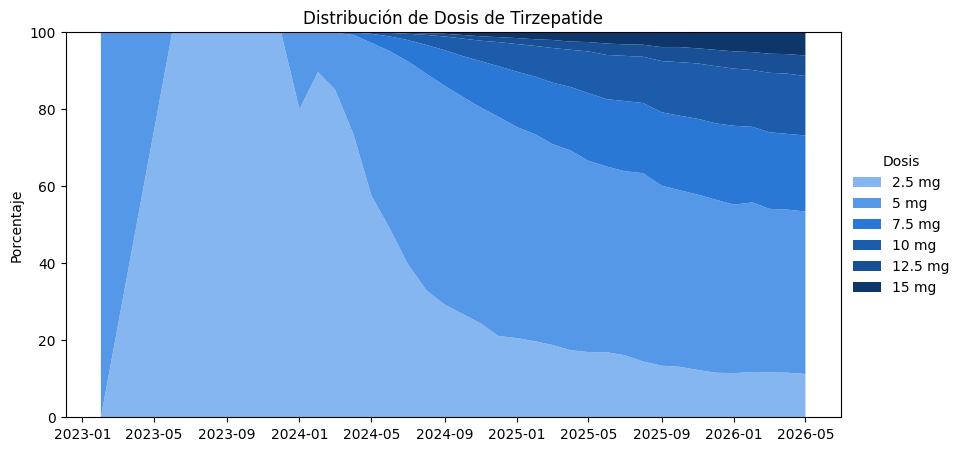

In [10]:
import matplotlib.pyplot as plt

print(mezcla_pct.round(1).head(6))    
colores = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#184f95', '#0d366b']   # de dosis baja (claro) a alta (oscuro)

fig, ax = plt.subplots(figsize=(10, 5))
ax.stackplot(mezcla_pct.index,
             [mezcla_pct[d] for d in mezcla_pct.columns],
             labels=[f"{d:g} mg" for d in mezcla_pct.columns],
             colors=colores)
ax.set_ylim(0, 100)         
ax.set_ylabel('Porcentaje')        
ax.set_title('Distribución de Dosis de Tirzepatide')         
ax.legend(title='Dosis', loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
fig.savefig('p9_mezcla_dosis.png', dpi=200, bbox_inches='tight')
plt.show()

In [11]:
print(mezcla.sum(axis=1).head(12))
print(mezcla.sum(axis=1).tail(3))

FECHA
2023-02-01        1
2023-06-01        1
2023-08-01        1
2023-10-01        1
2023-11-01        2
2023-12-01        3
2024-01-01        5
2024-02-01      261
2024-03-01     2827
2024-04-01    12317
2024-05-01    26167
2024-06-01    40370
dtype: int64
FECHA
2026-03-01    206094
2026-04-01    199825
2026-05-01    208979
dtype: int64


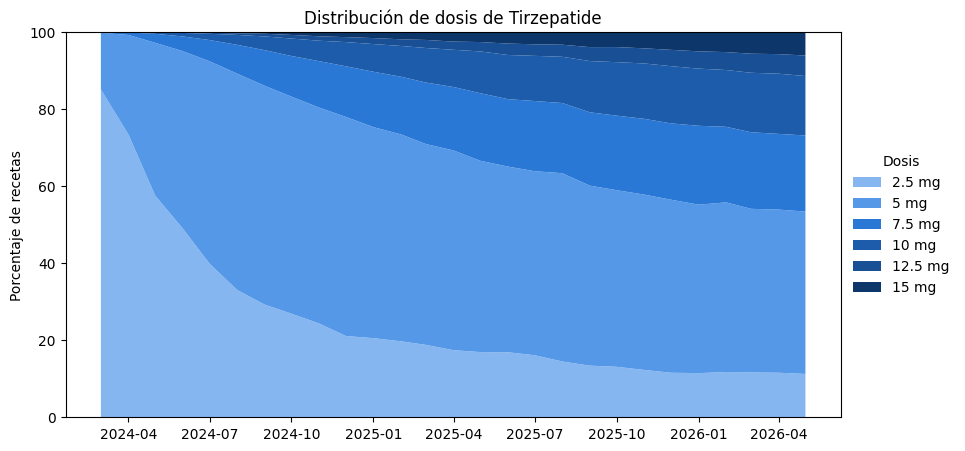

In [12]:
mezcla_pct2 = mezcla_pct.loc['2024-03':]

fig, ax = plt.subplots(figsize=(10, 5))
ax.stackplot(mezcla_pct2.index,
             [mezcla_pct2[d] for d in mezcla_pct2.columns],
             labels=[f"{d:g} mg" for d in mezcla_pct2.columns],
             colors=colores)
ax.set_ylim(0, 100)
ax.set_ylabel('Porcentaje de recetas')
ax.set_title('Distribución de dosis de Tirzepatide')  
ax.legend(title='Dosis', loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
fig.savefig('p9_mezcla_dosis.png', dpi=200, bbox_inches='tight')
plt.show()

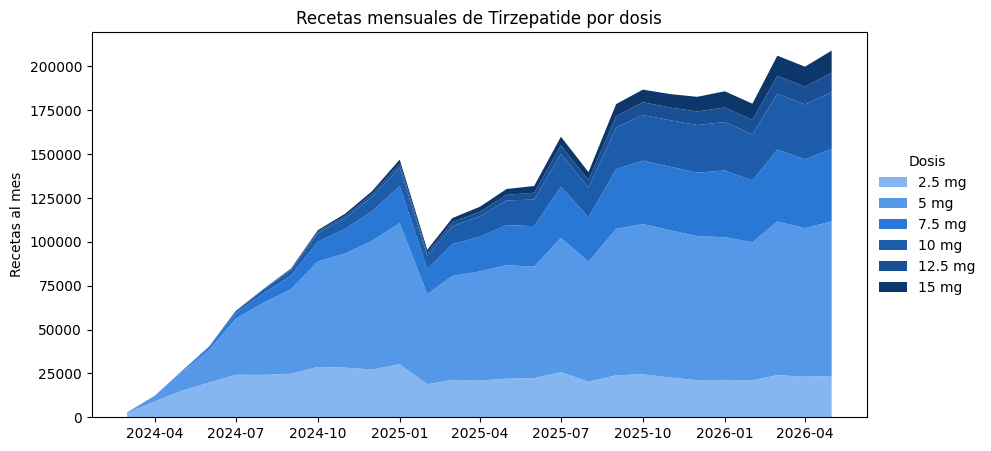

In [13]:
mezcla2 = mezcla.loc['2024-03':]

fig, ax = plt.subplots(figsize=(10, 5))
ax.stackplot(mezcla2.index,
             [mezcla2[d] for d in mezcla2.columns],
             labels=[f"{d:g} mg" for d in mezcla2.columns],
             colors=colores)
#ax.set_ylim(0, 100)
ax.set_ylabel('Recetas al mes')
ax.set_title('Recetas mensuales de Tirzepatide por dosis')
ax.legend(title='Dosis', loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
fig.savefig('p9_mezcla_dosis_volumen.png', dpi=200, bbox_inches='tight')
plt.show()

In [15]:
%pip install wordcloud

Using cached wordcloud-1.9.6-cp313-cp313-win_amd64.whl (306 kB)
Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


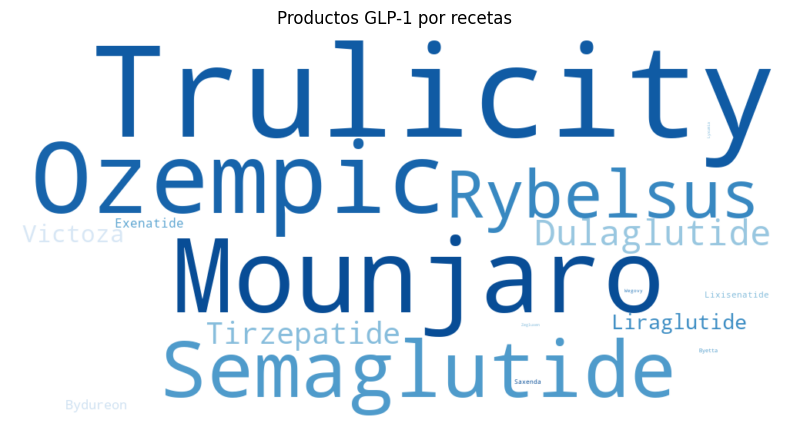

In [16]:
from wordcloud import WordCloud

frecuencias = df_final.groupby('PRIMERA_PALABRA')['ITEMS'].sum().to_dict()   

nube = WordCloud(width=1000, height=500, background_color='white', colormap='Blues').generate_from_frequencies(frecuencias)

plt.figure(figsize=(10, 5))
plt.imshow(nube, interpolation='bilinear')
plt.axis('off')
plt.title('Productos GLP-1 por recetas')   
plt.savefig('p9_nube_recetas.png', dpi=200, bbox_inches='tight')
plt.show()

In [22]:
df_final.groupby('SUSTANCIA')['ITEMS'].sum().sort_values(ascending=False)

SUSTANCIA
Semaglutide     4955543
Dulaglutide     4892294
Tirzepatide     3401069
Liraglutide     1080647
Exenatide        255509
Lixisenatide      56422
Name: ITEMS, dtype: int64

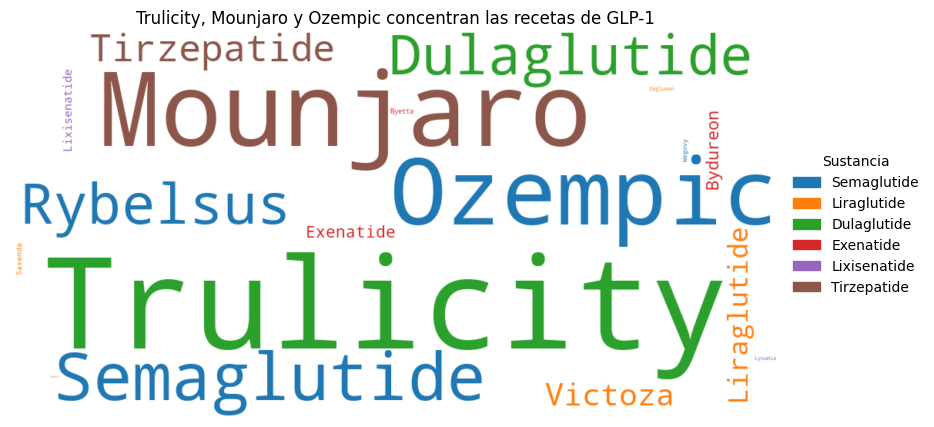

In [25]:
import matplotlib.colors as mcolors
from matplotlib.patches import Patch

# si no la tienes en este notebook, defínela como en la Práctica 3
sustancias_orden = ['Semaglutide', 'Liraglutide', 'Dulaglutide', 'Exenatide', 'Lixisenatide', 'Tirzepatide']
color_sustancia = dict(zip(sustancias_orden, plt.cm.tab10.colors))

# a qué sustancia pertenece cada primera palabra
mapa_sustancia = df_final.drop_duplicates('PRIMERA_PALABRA').set_index('PRIMERA_PALABRA')['SUSTANCIA'].to_dict()

def color_por_sustancia(word, **kwargs):
    return mcolors.to_hex(color_sustancia[mapa_sustancia[word]])

nube = WordCloud(width=1000, height=500, background_color='white',
                 color_func=color_por_sustancia).generate_from_frequencies(frecuencias)   # pista: la función que acabas de definir

plt.figure(figsize=(10, 5))
plt.imshow(nube, interpolation='bilinear')
plt.axis('off')
plt.title('Trulicity, Mounjaro y Ozempic concentran las recetas de GLP-1')   # tu título
leyenda = [Patch(color=mcolors.to_hex(c), label=s) for s, c in color_sustancia.items()]
plt.legend(handles=leyenda, loc='center left', bbox_to_anchor=(1, 0.5), frameon=False, title='Sustancia')
plt.savefig('p9_nube_recetas.png', dpi=200, bbox_inches='tight')
plt.show()

In [26]:
frecuencias_s = pd.Series(frecuencias).sort_values(ascending=False)
print(frecuencias_s.head(3).sum() / frecuencias_s.sum() * 100)

58.874619539931885


In [27]:
marca = df_final.groupby(['SUSTANCIA', 'ES_COMERCIAL'])['ITEMS'].sum().unstack(fill_value=0)   # pista: función que suma
marca_pct = marca.div(marca.sum(axis=1), axis=0) * 100                                         # pista: total por sustancia
print(marca_pct.round(1))

ES_COMERCIAL  False  True 
SUSTANCIA                 
Dulaglutide    21.2   78.8
Exenatide      45.5   54.5
Liraglutide    41.3   58.7
Lixisenatide   86.5   13.5
Semaglutide    30.5   69.5
Tirzepatide    29.0   71.0


In [28]:
df_final.groupby('PRIMERA_PALABRA')['FECHA'].min().sort_values()

PRIMERA_PALABRA
Bydureon       2021-01-01
Byetta         2021-01-01
Victoza        2021-01-01
Dulaglutide    2021-01-01
Exenatide      2021-01-01
Liraglutide    2021-01-01
Lixisenatide   2021-01-01
Lyxumia        2021-01-01
Trulicity      2021-01-01
Ozempic        2021-01-01
Rybelsus       2021-01-01
Saxenda        2021-01-01
Semaglutide    2021-01-01
Tirzepatide    2023-02-01
Wegovy         2023-10-01
Mounjaro       2023-11-01
Biolide        2024-11-01
Diavic         2024-12-01
Nevolat        2025-02-01
Zegluxen       2025-02-01
Name: FECHA, dtype: datetime64[ns]